In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, roc_auc_score, roc_curve
)

import joblib

sns.set_theme(style="whitegrid")
%matplotlib inline

In [40]:
df = pd.read_csv("food_delivery_orders_dataset.csv")

print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")

print("\n Data Information & Data Types: ")
df.info()

print("\n First 5 Rows: ")
df.head()

Dataset Shape: 50000 rows, 37 columns

 Data Information & Data Types: 
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 37 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   order_id                             50000 non-null  str    
 1   customer_id                          50000 non-null  str    
 2   restaurant_id                        50000 non-null  str    
 3   driver_id                            50000 non-null  str    
 4   order_timestamp                      50000 non-null  str    
 5   order_date                           50000 non-null  str    
 6   order_hour                           50000 non-null  int64  
 7   day_of_week                          50000 non-null  str    
 8   is_weekend                           50000 non-null  int64  
 9   city                                 50000 non-null  str    
 10  delivery_area                    

,order_id,customer_id,restaurant_id,driver_id,order_timestamp,order_date,order_hour,day_of_week,is_weekend,city,...,traffic_level,delivery_partner_experience_months,delivery_partner_rating,restaurant_preparation_time_minutes,estimated_delivery_time_minutes,actual_delivery_time_minutes,late_delivery,order_status,cancellation_reason,customer_rating
0,ORD_000001,CUS_00001,RES_0008,DRV_0075,2025-10-05 15:54:00,2025-10-05,15,Sunday,1,City_C,...,Medium,14,4.4,25,25,29.0,0.0,Completed,NaN,4.6
1,ORD_000002,CUS_00013,RES_0024,DRV_0131,2025-10-01 20:00:00,2025-10-01,20,Wednesday,0,City_A,...,High,44,4.7,12,20,24.0,0.0,Completed,NaN,5.0
2,ORD_000003,CUS_00049,RES_0013,DRV_0087,2025-10-07 18:24:00,2025-10-07,18,Tuesday,0,City_C,...,High,1,5.0,11,63,72.0,1.0,Completed,NaN,3.6
3,ORD_000004,CUS_00007,RES_0001,DRV_0177,2025-10-30 16:54:00,2025-10-30,16,Thursday,0,City_A,...,Low,50,4.3,12,23,31.0,1.0,Completed,NaN,4.1
4,ORD_000005,CUS_00325,RES_0029,DRV_0114,2025-10-15 18:34:00,2025-10-15,18,Wednesday,0,City_B,...,Medium,21,4.0,9,32,42.0,1.0,Completed,NaN,3.9


Numerical Features Summary Statistics: 


,order_hour,is_weekend,customer_age,restaurant_rating,items_count,subtotal,discount_percent,tax_amount,service_fee,delivery_fee,order_total,tip_amount,distance_km,delivery_partner_experience_months,delivery_partner_rating,restaurant_preparation_time_minutes,estimated_delivery_time_minutes,actual_delivery_time_minutes,late_delivery,customer_rating
count,50000.000000,50000.00000,50000.000000,50000.000000,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,49132.000000,50000.000000,50000.0000,50000.000000,50000.000000,50000.000000,49132.000000,49132.000000,49132.000000
mean,14.465900,0.26712,27.686580,4.207956,2.91002,30.897938,4.495700,4.128796,1.474600,3.075108,38.169501,1.610076,4.730632,29.7332,4.495062,15.549600,30.950580,35.152365,0.365709,4.295946
std,5.231155,0.44246,7.537796,0.450977,2.02907,27.068965,6.430008,3.636275,1.378101,2.299115,31.054669,2.878464,2.780190,17.4052,0.349198,7.360099,12.825519,14.701154,0.481633,0.530947
min,0.000000,0.00000,18.000000,2.800000,1.00000,5.100000,0.000000,0.570000,0.130000,0.000000,4.870000,0.000000,0.800000,1.0000,3.200000,5.000000,8.000000,10.000000,0.000000,1.800000
25%,11.000000,0.00000,21.000000,3.900000,1.00000,13.100000,0.000000,1.730000,0.580000,0.000000,17.430000,0.000000,2.800000,14.0000,4.300000,10.000000,22.000000,25.000000,0.000000,4.000000
50%,14.000000,0.00000,27.000000,4.200000,2.00000,22.825000,0.000000,2.890000,1.040000,3.500000,28.350000,0.000000,4.100000,29.0000,4.500000,14.000000,28.000000,33.000000,0.000000,4.400000
75%,19.000000,1.00000,33.000000,4.600000,4.00000,40.120000,10.000000,5.390000,1.890000,4.500000,48.660000,2.280000,5.900000,44.0000,4.800000,19.000000,37.000000,42.000000,1.000000,4.700000
max,23.000000,1.00000,55.000000,5.000000,10.00000,362.980000,20.000000,50.820000,25.210000,12.000000,443.210000,53.650000,20.000000,60.0000,5.000000,73.000000,128.000000,172.000000,1.000000,5.000000


Categorical Features Summary Statistics: 


,order_id,customer_id,restaurant_id,driver_id,order_timestamp,order_date,day_of_week,city,delivery_area,customer_type,restaurant_type,restaurant_primary_category,payment_method,weather,traffic_level,order_status,cancellation_reason
count,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,868
unique,50000,4979,250,200,25459,30,7,4,40,3,4,6,3,4,3,2,5
top,ORD_000001,CUS_00001,RES_0001,DRV_0066,2025-10-19 13:00:00,2025-10-23,Thursday,City_A,City_A_Area_1,Regular,Fast Food,Burger,Credit Card,Clear,Medium,Completed,Driver Unassigned
freq,1,4510,8837,315,9,1741,8472,19888,2056,25098,27593,16184,24971,28248,19522,49132,386


Features with Missing Values: 
tip_amount                        868
actual_delivery_time_minutes      868
late_delivery                     868
cancellation_reason             49132
customer_rating                   868
dtype: int64


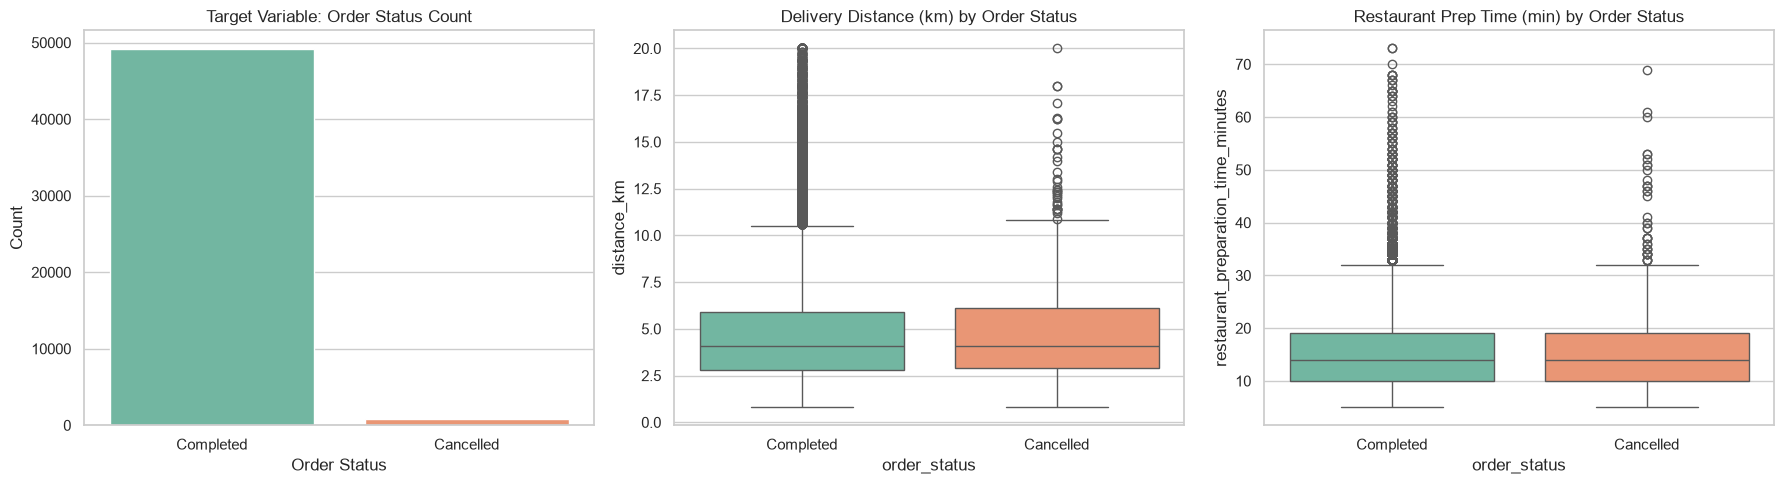

In [41]:
# Summary Statistics for Numerical Features
print("Numerical Features Summary Statistics: ")
display(df.describe())

# Summary Statistics for Categorical Features (Updated for Pandas 3 compatibility)
print("Categorical Features Summary Statistics: ")
display(df.describe(include=['object', 'string']))

# Missing Value Analysis
missing_vals = df.isnull().sum()
print("Features with Missing Values: ")
print(missing_vals[missing_vals > 0])

# Visualization: Target Distribution and Key Predictors (Updated for Seaborn 0.13+ syntax)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Target Variable Distribution
sns.countplot(data=df, x='order_status', hue='order_status', ax=axes[0], palette='Set2')
axes[0].set_title('Target Variable: Order Status Count')
axes[0].set_xlabel('Order Status')
axes[0].set_ylabel('Count')

# Distance (km) vs Order Status
sns.boxplot(data=df, x='order_status', y='distance_km', hue='order_status', ax=axes[1], palette='Set2')
axes[1].set_title('Delivery Distance (km) by Order Status')

# Preparation Time vs Order Status
sns.boxplot(data=df, x='order_status', y='restaurant_preparation_time_minutes', hue='order_status', ax=axes[2], palette='Set2')
axes[2].set_title('Restaurant Prep Time (min) by Order Status')

# Remove duplicate legends added by hue
for ax in axes:
    if ax.get_legend() is not None:
        ax.get_legend().remove()

plt.tight_layout()
plt.show()

In [42]:
# copy of the dataset
df_clean = df.copy()

# Check for duplicate 
duplicates_count = df_clean.duplicated().sum()
print(f"Number of duplicate rows: {duplicates_count}")
if duplicates_count > 0:
    df_clean.drop_duplicates(inplace=True)

# Verify clean dataset 
print(f"Cleaned dataset shape: {df_clean.shape}")

Number of duplicate rows: 0
Cleaned dataset shape: (50000, 37)


In [43]:
target_col = 'order_status'

leakage_and_ids = [
    'order_id', 'customer_id', 'restaurant_id', 'driver_id',
    'actual_delivery_time_minutes', 'late_delivery', 'cancellation_reason',
    'customer_rating', 'tip_amount', 'order_date'
]

X_raw = df_clean.drop(columns=[col for col in leakage_and_ids + [target_col] if col in df_clean.columns])

y = (df_clean[target_col] == 'Cancelled').astype(int)

print(f"Features shape after removing leakage columns: {X_raw.shape}")
print(f"Target distribution (1=Cancelled, 0=Completed):\n{y.value_counts()}")

Features shape after removing leakage columns: (50000, 26)
Target distribution (1=Cancelled, 0=Completed):
order_status
0    49132
1      868
Name: count, dtype: int64


In [54]:
def engineer_features(data):
    X = data.copy()
    
    if 'order_timestamp' in X.columns:
        X['order_timestamp'] = pd.to_datetime(X['order_timestamp'])
        X['is_peak_hour'] = X['order_hour'].isin([12, 13, 14, 19, 20, 21]).astype(int)
        X = X.drop(columns=['order_timestamp'])
    
    if 'subtotal' in X.columns and 'items_count' in X.columns:
        X['price_per_item'] = X['subtotal'] / X['items_count'].replace(0, 1)
# Task1:
    if 'delivery_fee' in X.columns and 'order_total' in X.columns:
        X['delivery_fee_ratio'] = X['delivery_fee'] / X['order_total'].replace(0, 1)
        
    return X

X_engineered = engineer_features(X_raw)

print("Engineered dataset preview:")
display(X_engineered.head(3))

Engineered dataset preview:


,order_hour,day_of_week,is_weekend,city,delivery_area,customer_age,customer_type,restaurant_type,restaurant_primary_category,restaurant_rating,...,distance_km,weather,traffic_level,delivery_partner_experience_months,delivery_partner_rating,restaurant_preparation_time_minutes,estimated_delivery_time_minutes,is_peak_hour,price_per_item,delivery_fee_ratio
0,15,Sunday,1,City_C,City_C_Area_3,40,Premium,Casual Dining,Healthy,4.4,...,1.1,Rain,Medium,14,4.4,25,25,0,16.205,0.000000
1,20,Wednesday,0,City_A,City_A_Area_1,19,Regular,Cafe,Dessert,4.4,...,2.5,Cloudy,High,44,4.7,12,20,1,6.515,0.171595
2,18,Tuesday,0,City_C,City_C_Area_3,26,Regular,Fast Food,Dessert,4.8,...,11.8,Cloudy,High,1,5.0,11,63,0,10.120,0.419098


In [45]:
categorical_cols = X_engineered.select_dtypes(include=['object', 'category', 'string']).columns.tolist()
numerical_cols = X_engineered.select_dtypes(include=[np.number]).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols),
        ('num', StandardScaler(), numerical_cols)
    ]
)

X_train, X_test, y_train, y_test = train_test_split(
    X_engineered, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training Set: {X_train.shape[0]} rows, {X_train.shape[1]} features")
print(f"Testing Set:  {X_test.shape[0]} rows, {X_test.shape[1]} features")
print(f"\nTrain Class Breakdown:\n{y_train.value_counts(normalize=True)}")
print(f"\nTest Class Breakdown:\n{y_test.value_counts(normalize=True)}")

Training Set: 40000 rows, 28 features
Testing Set:  10000 rows, 28 features

Train Class Breakdown:
order_status
0    0.98265
1    0.01735
Name: proportion, dtype: float64

Test Class Breakdown:
order_status
0    0.9826
1    0.0174
Name: proportion, dtype: float64


In [46]:
baseline_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

baseline_pipeline.fit(X_train, y_train)

y_pred_base = baseline_pipeline.predict(X_test)

#Display Performance Metrics
print("BASELINE MODEL PERFORMANCE (Logistic Regression): ")
print(f"Accuracy Score: {accuracy_score(y_test, y_pred_base):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred_base, target_names=['Completed (0)', 'Cancelled (1)'], zero_division=0))

BASELINE MODEL PERFORMANCE (Logistic Regression): 
Accuracy Score: 0.9826

Classification Report:
               precision    recall  f1-score   support

Completed (0)       0.98      1.00      0.99      9826
Cancelled (1)       0.00      0.00      0.00       174

     accuracy                           0.98     10000
    macro avg       0.49      0.50      0.50     10000
 weighted avg       0.97      0.98      0.97     10000



In [47]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42)
}

results = []

for name, clf in models.items():
    pipe = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', clf)
    ])
    
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1] if hasattr(clf, "predict_proba") else None
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    roc = roc_auc_score(y_test, y_prob) if y_prob is not None else np.nan
    
    results.append({
        'Model': name,
        'Accuracy': round(acc, 4),
        'Precision': round(prec, 4),
        'Recall': round(rec, 4),
        'F1-Score': round(f1, 4),
        'ROC-AUC': round(roc, 4)
    })

comparison_df = pd.DataFrame(results)
print("MODEL PERFORMANCE COMPARISON TABLE: ")
display(comparison_df)

MODEL PERFORMANCE COMPARISON TABLE: 


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.6030,0.0229,0.523,0.0438,0.5794
1,Random Forest,0.9825,0.0000,0.000,0.0000,0.5631
2,Gradient Boosting,0.9816,0.0000,0.000,0.0000,0.6015


In [48]:
rf_tuning_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=-1))
])

param_grid = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [10, 20, None],
    'classifier__min_samples_split': [2, 5]
}

grid_search = GridSearchCV(
    estimator=rf_tuning_pipeline,
    param_grid=param_grid,
    cv=3,
    scoring='roc_auc',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_

print("GRIDSEARCHCV TUNING RESULTS: ")
print(f"Best ROC-AUC Score: {grid_search.best_score_:.4f}")
print(f"Best Hyperparameters:\n{grid_search.best_params_}")

GRIDSEARCHCV TUNING RESULTS: 
Best ROC-AUC Score: 0.5721
Best Hyperparameters:
{'classifier__max_depth': 10, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 100}


FINAL TUNED MODEL CLASSIFICATION REPORT: 
               precision    recall  f1-score   support

Completed (0)       0.98      0.88      0.93      9826
Cancelled (1)       0.03      0.21      0.05       174

     accuracy                           0.87     10000
    macro avg       0.51      0.54      0.49     10000
 weighted avg       0.97      0.87      0.91     10000



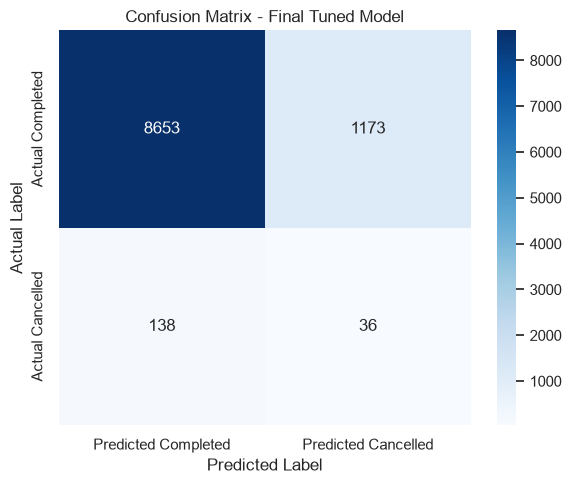

In [49]:
y_pred_best = best_model.predict(X_test)
y_prob_best = best_model.predict_proba(X_test)[:, 1]

print("FINAL TUNED MODEL CLASSIFICATION REPORT: ")
print(classification_report(y_test, y_pred_best, target_names=['Completed (0)', 'Cancelled (1)'], zero_division=0))

cm = confusion_matrix(y_test, y_pred_best)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Predicted Completed', 'Predicted Cancelled'],
            yticklabels=['Actual Completed', 'Actual Cancelled'])
plt.title('Confusion Matrix - Final Tuned Model')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.tight_layout()
plt.show()

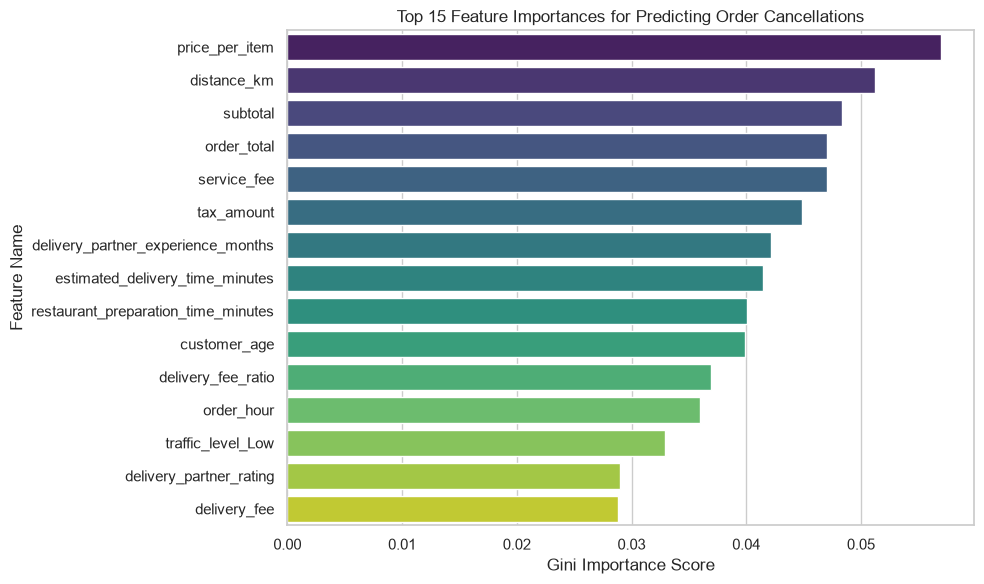

TOP 10 FEATURE IMPORTANCE RANKING: 


,Feature,Importance
0,price_per_item,0.057005
1,distance_km,0.051234
2,subtotal,0.048360
3,order_total,0.047039
4,service_fee,0.047026
5,tax_amount,0.044866
6,delivery_partner_experience_months,0.042125
7,estimated_delivery_time_minutes,0.041489
8,restaurant_preparation_time_minutes,0.040043
9,customer_age,0.039909


In [50]:
cat_encoder = best_model.named_steps['preprocessor'].named_transformers_['cat']
encoded_cat_cols = cat_encoder.get_feature_names_out(categorical_cols).tolist()
all_feature_names = encoded_cat_cols + numerical_cols

importances = best_model.named_steps['classifier'].feature_importances_

feature_imp_df = pd.DataFrame({
    'Feature': all_feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=feature_imp_df.head(15), x='Importance', y='Feature', hue='Feature', palette='viridis', legend=False)
plt.title('Top 15 Feature Importances for Predicting Order Cancellations')
plt.xlabel('Gini Importance Score')
plt.ylabel('Feature Name')
plt.tight_layout()
plt.show()

print("TOP 10 FEATURE IMPORTANCE RANKING: ")
display(feature_imp_df.head(10).reset_index(drop=True))

In [51]:
#Task 2: Alternative Peak Hour Rule Comparison
def engineer_features_alt(data):
    X = data.copy()
    if 'order_timestamp' in X.columns:
        X['order_timestamp'] = pd.to_datetime(X['order_timestamp'])
        # Alternative Rule: Strict evening dinner & rush surge (17:00 to 22:00)
        X['is_peak_hour'] = X['order_hour'].between(17, 22).astype(int)
        X = X.drop(columns=['order_timestamp'])
    
    if 'subtotal' in X.columns and 'items_count' in X.columns:
        X['price_per_item'] = X['subtotal'] / X['items_count'].replace(0, 1)
        
    if 'delivery_fee' in X.columns and 'order_total' in X.columns:
        X['delivery_fee_ratio'] = X['delivery_fee'] / X['order_total'].replace(0, 1)
        
    return X

X_alt_engineered = engineer_features_alt(X_raw)

X_train_alt, X_test_alt, y_train_alt, y_test_alt = train_test_split(
    X_alt_engineered, y, test_size=0.2, random_state=42, stratify=y
)

alt_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42, n_jobs=-1))
])

alt_pipeline.fit(X_train_alt, y_train_alt)
y_pred_alt = alt_pipeline.predict(X_test_alt)

print("TASK 2: ALTERNATIVE PEAK HOUR (17-22) PERFORMANCE")
print(f"Accuracy Score: {accuracy_score(y_test_alt, y_pred_alt):.4f}")
print("Classification Report:")
print(classification_report(y_test_alt, y_pred_alt, target_names=['Completed (0)', 'Cancelled (1)'], zero_division=0))

TASK 2: ALTERNATIVE PEAK HOUR (17-22) PERFORMANCE
Accuracy Score: 0.9826
Classification Report:
               precision    recall  f1-score   support

Completed (0)       0.98      1.00      0.99      9826
Cancelled (1)       0.00      0.00      0.00       174

     accuracy                           0.98     10000
    macro avg       0.49      0.50      0.50     10000
 weighted avg       0.97      0.98      0.97     10000



In [52]:
# Task 3: Varying top_k for High Cardinality Categorical Reduction

from sklearn.preprocessing import OneHotEncoder

def evaluate_top_k(k_val):
    X_k = X_raw.copy()
    
    # Apply top_k grouping on a high-cardinality feature like 'delivery_area' or 'restaurant_id'
    col_to_reduce = 'delivery_area'
    top_categories = X_k[col_to_reduce].value_counts().nlargest(k_val).index
    X_k[col_to_reduce] = X_k[col_to_reduce].where(X_k[col_to_reduce].isin(top_categories), 'Other')
    
    X_k['is_peak_hour'] = X_k['order_hour'].isin([12, 13, 14, 19, 20, 21]).astype(int)
    X_k['price_per_item'] = X_k['subtotal'] / X_k['items_count'].replace(0, 1)
    X_k['delivery_fee_ratio'] = X_k['delivery_fee'] / X_k['order_total'].replace(0, 1)
    if 'order_timestamp' in X_k.columns:
        X_k = X_k.drop(columns=['order_timestamp'])

    X_tr, X_te, y_tr, y_te = train_test_split(X_k, y, test_size=0.2, random_state=42, stratify=y)
    
    cat_cols_k = X_k.select_dtypes(include=['object', 'category', 'string']).columns.tolist()
    num_cols_k = X_k.select_dtypes(include=[np.number]).columns.tolist()
    
    prep_k = ColumnTransformer(transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols_k),
        ('num', StandardScaler(), num_cols_k)
    ])
    
    pipe_k = Pipeline([
        ('preprocessor', prep_k),
        ('classifier', RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42, n_jobs=-1))
    ])
    
    pipe_k.fit(X_tr, y_tr)
    preds = pipe_k.predict(X_te)
    acc = accuracy_score(y_te, preds)
    
    cat_enc = pipe_k.named_steps['preprocessor'].named_transformers_['cat']
    feat_names = cat_enc.get_feature_names_out(cat_cols_k).tolist() + num_cols_k
    importances = pipe_k.named_steps['classifier'].feature_importances_
    top_feat = pd.DataFrame({'Feature': feat_names, 'Importance': importances}).sort_values(by='Importance', ascending=False).iloc[0]['Feature']
    
    return acc, top_feat

print("TASK 3: COMPARING DIFFERENT top_k VALUES:")
for k in [10, 20, 40]:
    acc, top_f = evaluate_top_k(k)
    print(f"top_k = {k} ---> Accuracy: {acc:.4f} | Top Feature: {top_f}")

TASK 3: COMPARING DIFFERENT top_k VALUES:
top_k = 10 ---> Accuracy: 0.9825 | Top Feature: price_per_item
top_k = 20 ---> Accuracy: 0.9825 | Top Feature: price_per_item
top_k = 40 ---> Accuracy: 0.9825 | Top Feature: price_per_item


In [53]:
# Task 4: Optional Feature Selection using SelectFromModel 

from sklearn.feature_selection import SelectFromModel

X_train_encoded = preprocessor.fit_transform(X_train)
X_test_encoded = preprocessor.transform(X_test)

selector_clf = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42, n_jobs=-1)
feature_selector = SelectFromModel(estimator=selector_clf, threshold='median') # keeps features above median importance

X_train_selected = feature_selector.fit_transform(X_train_encoded, y_train)
X_test_selected = feature_selector.transform(X_test_encoded)

print(f"Original feature count: {X_train_encoded.shape[1]}")
print(f"Selected feature count: {X_train_selected.shape[1]}")

final_selected_clf = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42, n_jobs=-1)
final_selected_clf.fit(X_train_selected, y_train)

y_pred_sel = final_selected_clf.predict(X_test_selected)

print("\nTASK 4: PERFORMANCE AFTER FEATURE SELECTION: ")
print(f"Accuracy Score: {accuracy_score(y_test, y_pred_sel):.4f}")
print("Classification Report:")
print(classification_report(y_test, y_pred_sel, target_names=['Completed (0)', 'Cancelled (1)'], zero_division=0))

Original feature count: 93
Selected feature count: 47

TASK 4: PERFORMANCE AFTER FEATURE SELECTION: 
Accuracy Score: 0.9825
Classification Report:
               precision    recall  f1-score   support

Completed (0)       0.98      1.00      0.99      9826
Cancelled (1)       0.00      0.00      0.00       174

     accuracy                           0.98     10000
    macro avg       0.49      0.50      0.50     10000
 weighted avg       0.97      0.98      0.97     10000

